In [42]:
from IPython import display

In [43]:
!sudo apt-get update
!sudo apt-get install octave

display.clear_output()

In [44]:
!octave -version

display.clear_output()

In [45]:
!pip install oct2py

display.clear_output()

In [46]:
%load_ext oct2py.ipython

The oct2py.ipython extension is already loaded. To reload it, use:
  %reload_ext oct2py.ipython


In [47]:
%%writefile generate.m
function gamma = generate(A, gamma0, N)
    gamma = zeros(1, N);
    gamma(1) = gamma0; # в Octave индексация с 1
    for i = 2:N
        gamma(i) = A * gamma(i-1);
        gamma(i) = gamma(i) - floor(gamma(i));
    end
end

Overwriting generate.m


In [48]:
%%octave
#g = generate(5^13, 2^-36, 10000); # БЭСМ-4
#g = generate(5^17, 2^-40, 10000); # БЭСМ-6
g = generate(5^17, 2^-42, 10000); # Американские ЭВМ
disp(mean(g));
disp(var(g));
# интервал на котором лежат числа [0, 1)

0.4999

0.083123

Сортируем по возрастанию sort()

In [49]:
%%octave
x = sort(g);
disp(x(1))
disp(x(end))

2.2737e-13

0.9993

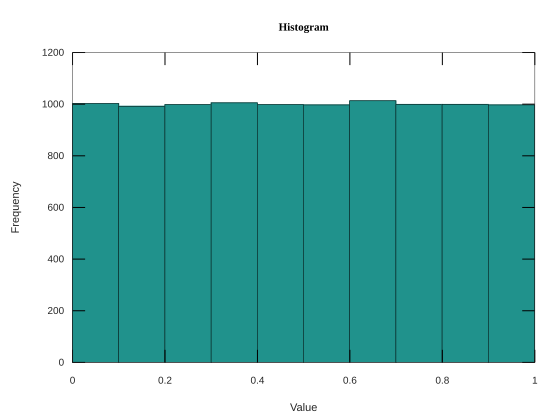

In [50]:
%%octave
graphics_toolkit("gnuplot");
hist(g, 10);
title('Histogram');
xlabel('Value');
ylabel('Frequency');

Из-за статистистического шума такая гистограмма. Чем больше N, тем меньше шум.

In [51]:
%%octave
n = length(g);
disp(n)

10000

Эмпирическая функция распределения:

In [52]:
%%octave
Fn = (1:n) / n;

Теоритическая функция
распределения:

In [53]:
%%octave
F = x;

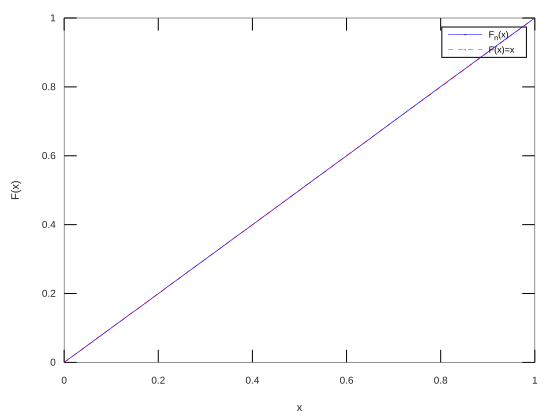

In [54]:
%%octave
plot(x, Fn, 'b', [0 1], [0 1], 'r--');
xlabel('x'); ylabel('F(x)');
legend('F_n(x)', 'F(x)=x');

Статистика Колмогорова:

In [55]:
%%octave
D = max(abs(Fn - F));
disp(D)

1.8059e-03

In [56]:
%%octave
alpha = 0.05;
Dcrit = sqrt(-0.5*log(alpha/2)) / sqrt(n);

In [60]:
%%octave
if D < Dcrit
    disp('Gipoteza o ravnomernosti NE otvergaetsya');
else
    disp('Gipoteza o ravnomernosti OTVERGAETSYA');
end

Gipoteza o ravnomernosti NE otvergaetsya